# A. Setup

#### 1. Imports + RESULTS_DIR + DATASETS

In [80]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Notebook:
# thesis/src/analysis/xai_results_analysis.ipynb

RESULTS_DIR = Path("../../results").resolve()

DATASETS = [
    "heart",
    "stroke",
    "diabetes",
    "ckd",
    "hba1c"
]

print("Results directory:", RESULTS_DIR)
print("Exists:", RESULTS_DIR.exists())

Results directory: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results
Exists: True


In [81]:
import sys
from pathlib import Path

FRAMEWORK_DIR = Path.cwd().parent / "xai_framework"

if str(FRAMEWORK_DIR) not in sys.path:
    sys.path.insert(0, str(FRAMEWORK_DIR))

#### 2. Check dataset folders

In [82]:
for dataset in DATASETS:

    dataset_dir = RESULTS_DIR / dataset

    print(
        dataset,
        "->",
        dataset_dir.exists(),
        dataset_dir
    )

heart -> True C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results\heart
stroke -> True C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results\stroke
diabetes -> True C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results\diabetes
ckd -> True C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results\ckd
hba1c -> True C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results\hba1c


#### 3. Helper for reading JSON scalar values

In [83]:
import json


def read_json_value(path):

    if not path.exists():
        return np.nan

    with open(path, "r") as f:
        value = json.load(f)

    # Handle either a scalar JSON value
    # or a dictionary containing one value
    if isinstance(value, dict):

        if len(value) == 1:
            return next(iter(value.values()))

        return value

    return value

#### 4. Helper for reading metadata

In [84]:
def load_metadata(dataset):

    path = (
        RESULTS_DIR
        / dataset
        / "bundle"
        / "metadata.json"
    )

    if not path.exists():
        return {}

    with open(path, "r") as f:
        return json.load(f)

#### 5. Helper for stability results

In [85]:
def load_stability_summary(dataset):

    path = (
        RESULTS_DIR
        / dataset
        / "stability_rank.csv"
    )

    if not path.exists():
        return {
            "MeanStabilityRho": np.nan,
            "MeanTopKOverlap": np.nan
        }

    df = pd.read_csv(path)

    mean_rho = (
        df["SpearmanRankCorrelation"].mean()
        if "SpearmanRankCorrelation" in df.columns
        else np.nan
    )

    mean_overlap = (
        df["TopKOverlap"].mean()
        if "TopKOverlap" in df.columns
        else np.nan
    )

    return {
        "MeanStabilityRho": mean_rho,
        "MeanTopKOverlap": mean_overlap
    }

# B. Cross-Dataset Summary

#### 1. Build summary_df

In [86]:
rows = []

for dataset in DATASETS:

    dataset_dir = RESULTS_DIR / dataset

    metadata = load_metadata(dataset)

    rank_dir = dataset_dir / "rank_agreement"

    native_shap = read_json_value(
        rank_dir / "Native_vs_SHAP.json"
    )

    native_perm = read_json_value(
        rank_dir / "Native_vs_Permutation.json"
    )

    shap_perm = read_json_value(
        rank_dir / "SHAP_vs_Permutation.json"
    )

    stability = load_stability_summary(dataset)

    # Get feature count from metadata if available.
    # Otherwise read X_test.
    n_features = metadata.get("n_features", np.nan)

    if pd.isna(n_features):

        x_test_path = (
            dataset_dir
            / "bundle"
            / "X_test.csv"
        )

        if x_test_path.exists():

            X_test_tmp = pd.read_csv(x_test_path)

            # Depending on how y/index were saved this normally
            # corresponds directly to the feature count.
            n_features = X_test_tmp.shape[1]

    rows.append({
        "Dataset": dataset.capitalize(),
        "Model": metadata.get("model", "Unknown"),
        "Features": n_features,

        "Native_SHAP_Rho": native_shap,
        "Native_Permutation_Rho": native_perm,
        "SHAP_Permutation_Rho": shap_perm,

        "Mean_Stability_Rho":
            stability["MeanStabilityRho"],

        "Mean_TopK_Overlap":
            stability["MeanTopKOverlap"]
    })


summary_df = pd.DataFrame(rows)

summary_df["Dataset"] = summary_df["Dataset"].replace({
    "Ckd": "CKD",
    "Hba1c": "HbA1c"
})

display(summary_df.round(3))

,Dataset,Model,Features,Native_SHAP_Rho,Native_Permutation_Rho,SHAP_Permutation_Rho,Mean_Stability_Rho,Mean_TopK_Overlap
0,Heart,LogisticRegressionCV,13,0.995,0.956,0.951,0.915,0.800
1,Stroke,LogisticRegression,7,0.964,0.643,0.679,0.793,0.800
2,Diabetes,RandomForestClassifier,5,1.000,1.000,1.000,0.960,0.867
3,CKD,RandomForestClassifier,24,0.981,0.575,0.570,0.341,0.567
4,HbA1c,BinaryResultsWrapper,91,0.047,0.409,0.883,NaN,NaN


#### 2. Check for missing values

In [87]:
print(summary_df.isna().sum())

display(summary_df)

Dataset                   0
Model                     0
Features                  0
Native_SHAP_Rho           0
Native_Permutation_Rho    0
SHAP_Permutation_Rho      0
Mean_Stability_Rho        1
Mean_TopK_Overlap         1
dtype: int64


,Dataset,Model,Features,Native_SHAP_Rho,Native_Permutation_Rho,SHAP_Permutation_Rho,Mean_Stability_Rho,Mean_TopK_Overlap
0,Heart,LogisticRegressionCV,13,0.994505,0.956044,0.950549,0.914835,0.800000
1,Stroke,LogisticRegression,7,0.964286,0.642857,0.678571,0.792727,0.800000
2,Diabetes,RandomForestClassifier,5,1.000000,1.000000,1.000000,0.960000,0.866667
3,CKD,RandomForestClassifier,24,0.980870,0.574783,0.570435,0.341086,0.566667
4,HbA1c,BinaryResultsWrapper,91,0.046631,0.408503,0.883294,NaN,NaN


#### 3. summary_display

In [88]:
summary_display = summary_df.copy()

summary_display["Mean_Stability_Rho"] = (
    summary_display["Mean_Stability_Rho"]
    .apply(
        lambda x: "N/A"
        if pd.isna(x)
        else f"{x:.3f}"
    )
)

summary_display["Mean_TopK_Overlap"] = (
    summary_display["Mean_TopK_Overlap"]
    .apply(
        lambda x: "N/A"
        if pd.isna(x)
        else f"{x:.3f}"
    )
)

display(summary_display)

,Dataset,Model,Features,Native_SHAP_Rho,Native_Permutation_Rho,SHAP_Permutation_Rho,Mean_Stability_Rho,Mean_TopK_Overlap
0,Heart,LogisticRegressionCV,13,0.994505,0.956044,0.950549,0.915,0.800
1,Stroke,LogisticRegression,7,0.964286,0.642857,0.678571,0.793,0.800
2,Diabetes,RandomForestClassifier,5,1.000000,1.000000,1.000000,0.960,0.867
3,CKD,RandomForestClassifier,24,0.980870,0.574783,0.570435,0.341,0.567
4,HbA1c,BinaryResultsWrapper,91,0.046631,0.408503,0.883294,N/A,N/A


#### 4. Load importance tables

In [89]:
def load_importance_tables(dataset):

    dataset_dir = RESULTS_DIR / dataset

    paths = {
        "Native":
            dataset_dir / "native_importance.csv",

        "Permutation":
            dataset_dir / "permutation_importance.csv",

        "SHAP":
            dataset_dir / "shap_importance.csv"
    }

    tables = {}

    for method, path in paths.items():

        if path.exists():
            tables[method] = pd.read_csv(path)
        else:
            tables[method] = None

    return tables

#### 5. Extract top 5 features

In [90]:
def get_top_features(dataset, top_n=5):

    tables = load_importance_tables(dataset)

    rows = []

    for method, df in tables.items():

        if df is None or df.empty:
            continue

        if method == "SHAP":
            importance_col = "MeanAbsSHAP"

        else:
            importance_col = "Importance"

        if importance_col not in df.columns:
            continue

        top = (
            df
            .sort_values(
                importance_col,
                ascending=False
            )
            .head(top_n)
        )

        for rank, (_, row) in enumerate(
            top.iterrows(),
            start=1
        ):

            rows.append({
                "Dataset": dataset.capitalize(),
                "Method": method,
                "Rank": rank,
                "Feature": row["Feature"],
                "Importance": row[importance_col]
            })

    return pd.DataFrame(rows)

#### 6. Combine all top features

In [91]:
top_feature_frames = []

for dataset in DATASETS:

    top_df = get_top_features(
        dataset,
        top_n=5
    )

    top_feature_frames.append(top_df)


top_features_df = pd.concat(
    top_feature_frames,
    ignore_index=True
)

display(top_features_df)

,Dataset,Method,Rank,Feature,Importance
0,Heart,Native,1,thal,0.478765
1,Heart,Native,2,ca,0.444304
2,Heart,Native,3,cp,0.334345
3,Heart,Native,4,exang,0.312199
4,Heart,Native,5,sex,0.282055
...,...,...,...,...,...
70,Hba1c,SHAP,1,time_in_hospital,0.025383
71,Hba1c,SHAP,2,specialty_group[T.Missing or unknown],0.017392
72,Hba1c,SHAP,3,discharge_group[T.Otherwise],0.011744
73,Hba1c,SHAP,4,specialty_group[T.Missing or unknown]:time_in_...,0.011396


#### 7. Compact table top 5 features

In [92]:
top5_table = (
    top_features_df
    .pivot_table(
        index=["Dataset", "Rank"],
        columns="Method",
        values="Feature",
        aggfunc="first"
    )
    .reset_index()
)

display(top5_table)

Method,Dataset,Rank,Native,Permutation,SHAP
0,Ckd,1,sc,sg,sg
1,Ckd,2,sg,sc,sc
2,Ckd,3,hemo,pcv,hemo
3,Ckd,4,pcv,rc,pcv
4,Ckd,5,al,al,al
5,Diabetes,1,Glucose,Glucose,Glucose
6,Diabetes,2,BMI,BMI,BMI
7,Diabetes,3,Age,Age,Age
8,Diabetes,4,Insulin,Insulin,Insulin
9,Diabetes,5,SkinThickness,SkinThickness,SkinThickness


#### 13. Plot rank agreement across datasets

In [93]:
agreement_plot_df = summary_df[
    [
        "Dataset",
        "Native_SHAP_Rho",
        "Native_Permutation_Rho",
        "SHAP_Permutation_Rho"
    ]
].copy()

agreement_plot_df = agreement_plot_df.melt(
    id_vars="Dataset",
    var_name="Comparison",
    value_name="SpearmanRho"
)

display(agreement_plot_df)

,Dataset,Comparison,SpearmanRho
0,Heart,Native_SHAP_Rho,0.994505
1,Stroke,Native_SHAP_Rho,0.964286
2,Diabetes,Native_SHAP_Rho,1.000000
3,CKD,Native_SHAP_Rho,0.980870
4,HbA1c,Native_SHAP_Rho,0.046631
5,Heart,Native_Permutation_Rho,0.956044
6,Stroke,Native_Permutation_Rho,0.642857
7,Diabetes,Native_Permutation_Rho,1.000000
8,CKD,Native_Permutation_Rho,0.574783
9,HbA1c,Native_Permutation_Rho,0.408503


#### 8. Rank agreement plot

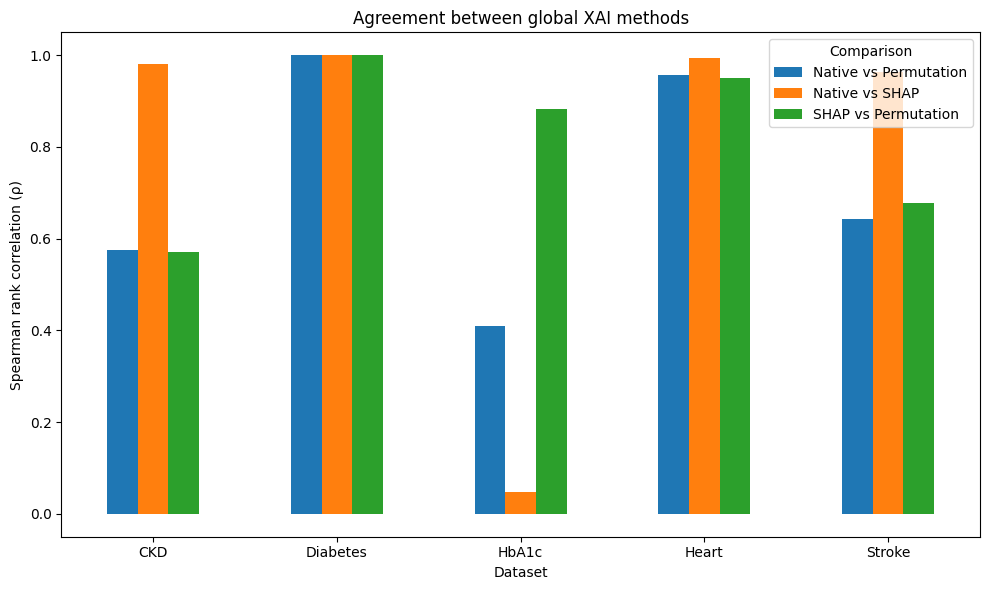

In [94]:
plot_df = agreement_plot_df.copy()

plot_df["Comparison"] = plot_df["Comparison"].replace({
    "Native_SHAP_Rho": "Native vs SHAP",
    "Native_Permutation_Rho": "Native vs Permutation",
    "SHAP_Permutation_Rho": "SHAP vs Permutation"
})

pivot_df = plot_df.pivot(
    index="Dataset",
    columns="Comparison",
    values="SpearmanRho"
)

ax = pivot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Spearman rank correlation (ρ)")
ax.set_xlabel("Dataset")
ax.set_title("Agreement between global XAI methods")

plt.xticks(rotation=0)
plt.legend(title="Comparison")
plt.tight_layout()
plt.show()

#### 9. Stability comparison

In [95]:
stability_plot_df = summary_df[
    summary_df["Mean_Stability_Rho"].notna()
].copy()

display(
    stability_plot_df[
        [
            "Dataset",
            "Mean_Stability_Rho",
            "Mean_TopK_Overlap"
        ]
    ].round(3)
)

,Dataset,Mean_Stability_Rho,Mean_TopK_Overlap
0,Heart,0.915,0.800
1,Stroke,0.793,0.800
2,Diabetes,0.960,0.867
3,CKD,0.341,0.567


#### 10. Stability rank correlation

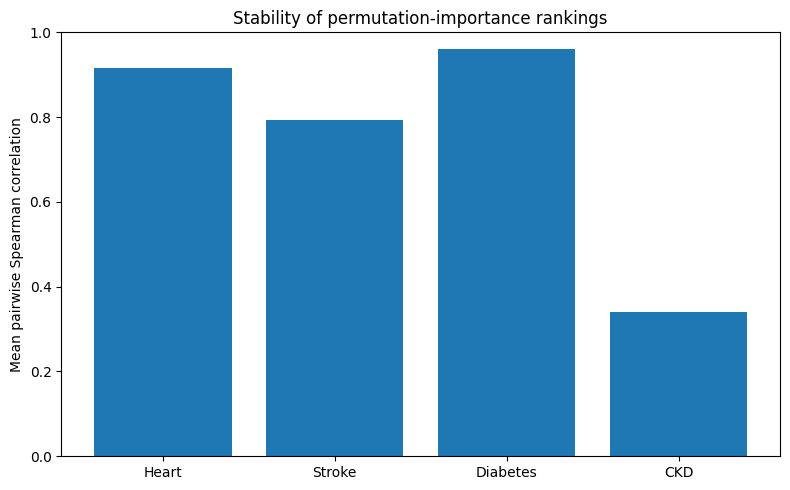

In [96]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    stability_plot_df["Dataset"],
    stability_plot_df["Mean_Stability_Rho"]
)

ax.set_ylim(0, 1)

ax.set_ylabel(
    "Mean pairwise Spearman correlation"
)

ax.set_title(
    "Stability of permutation-importance rankings"
)

plt.tight_layout()
plt.show()

#### 11. Top-3 overlap stability

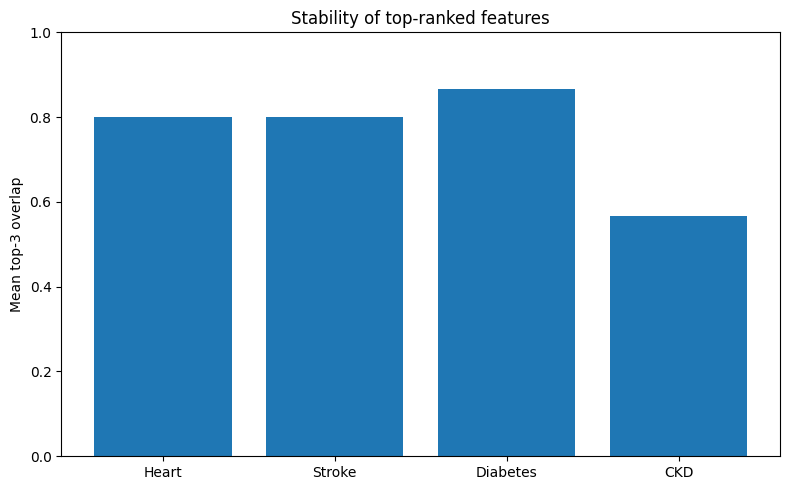

In [97]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    stability_plot_df["Dataset"],
    stability_plot_df["Mean_TopK_Overlap"]
)

ax.set_ylim(0, 1)

ax.set_ylabel("Mean top-3 overlap")

ax.set_title(
    "Stability of top-ranked features"
)

plt.tight_layout()
plt.show()

#### 12. Saved Results

In [98]:
ANALYSIS_OUT = RESULTS_DIR / "cross_dataset"

ANALYSIS_OUT.mkdir(
    parents=True,
    exist_ok=True
)

In [99]:
summary_df.to_csv(
    ANALYSIS_OUT / "xai_summary.csv",
    index=False
)

top_features_df.to_csv(
    ANALYSIS_OUT / "top_features_all_methods.csv",
    index=False
)

top5_table.to_csv(
    ANALYSIS_OUT / "top5_feature_comparison.csv",
    index=False
)

agreement_plot_df.to_csv(
    ANALYSIS_OUT / "rank_agreement_all_datasets.csv",
    index=False
)

stability_plot_df.to_csv(
    ANALYSIS_OUT / "stability_comparison.csv",
    index=False
)

print(
    "Cross-dataset results saved to:",
    ANALYSIS_OUT
)

Cross-dataset results saved to: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results\cross_dataset


# C. Global XAI Analysis

#### 1. Per-dataset global XAI comparison

In [100]:
def load_global_tables(dataset):

    dataset_dir = RESULTS_DIR / dataset

    native = pd.read_csv(
        dataset_dir / "native_importance.csv"
    )

    permutation = pd.read_csv(
        dataset_dir / "permutation_importance.csv"
    )

    shap = pd.read_csv(
        dataset_dir / "shap_importance.csv"
    )

    # Exclude model constants from XAI feature comparisons
    for df in [native, permutation, shap]:

        df.drop(
            df[
                df["Feature"]
                .astype(str)
                .str.lower()
                .isin(["intercept", "const"])
            ].index,
            inplace=True
        )

    return native, permutation, shap

In [101]:
def global_rank_table(dataset):

    native, permutation, shap = load_global_tables(dataset)

    native_df = (
        native[["Feature", "Importance"]]
        .rename(columns={"Importance": "NativeImportance"})
        .copy()
    )

    permutation_df = (
        permutation[["Feature", "Importance"]]
        .rename(columns={"Importance": "PermutationImportance"})
        .copy()
    )

    shap_df = (
        shap[["Feature", "MeanAbsSHAP"]]
        .rename(columns={"MeanAbsSHAP": "SHAPImportance"})
        .copy()
    )

    merged = (
        native_df
        .merge(
            permutation_df,
            on="Feature",
            how="inner"
        )
        .merge(
            shap_df,
            on="Feature",
            how="inner"
        )
    )

    merged["NativeRank"] = (
        merged["NativeImportance"]
        .rank(ascending=False, method="min")
    )

    merged["PermutationRank"] = (
        merged["PermutationImportance"]
        .rank(ascending=False, method="min")
    )

    merged["SHAPRank"] = (
        merged["SHAPImportance"]
        .rank(ascending=False, method="min")
    )

    merged["MeanRank"] = merged[
        [
            "NativeRank",
            "PermutationRank",
            "SHAPRank"
        ]
    ].mean(axis=1)

    merged["RankRange"] = (
        merged[
            [
                "NativeRank",
                "PermutationRank",
                "SHAPRank"
            ]
        ].max(axis=1)
        -
        merged[
            [
                "NativeRank",
                "PermutationRank",
                "SHAPRank"
            ]
        ].min(axis=1)
    )

    return merged.sort_values("MeanRank")

In [102]:
for dataset in DATASETS:

    print("\n" + "=" * 70)
    print(dataset.upper())
    print("=" * 70)

    table = global_rank_table(dataset)

    display(
        table[
            [
                "Feature",
                "NativeRank",
                "PermutationRank",
                "SHAPRank",
                "MeanRank",
                "RankRange"
            ]
        ]
        .head(10)
        .round(2)
    )


HEART


,Feature,NativeRank,PermutationRank,SHAPRank,MeanRank,RankRange
0,thal,1.0,2.0,1.0,1.33,1.0
1,ca,2.0,1.0,2.0,1.67,1.0
2,cp,3.0,3.0,3.0,3.00,0.0
3,exang,4.0,5.0,4.0,4.33,1.0
4,sex,5.0,4.0,5.0,4.67,1.0
5,oldpeak,6.0,7.0,6.0,6.33,1.0
6,thalach,7.0,6.0,7.0,6.67,1.0
7,restecg,8.0,9.0,8.0,8.33,1.0
9,trestbps,10.0,8.0,10.0,9.33,2.0
8,slope,9.0,11.0,9.0,9.67,2.0



STROKE


,Feature,NativeRank,PermutationRank,SHAPRank,MeanRank,RankRange
0,age,1.0,1.0,1.0,1.00,0.0
2,avg_glucose_level,3.0,2.0,2.0,2.33,1.0
1,bmi_missing,2.0,3.0,3.0,2.67,1.0
3,hypertension,4.0,7.0,4.0,5.00,3.0
4,ever_married_No,5.0,5.0,5.0,5.00,0.0
5,ever_married_Yes,6.0,5.0,6.0,5.67,1.0
6,heart_disease,7.0,4.0,7.0,6.00,3.0



DIABETES


,Feature,NativeRank,PermutationRank,SHAPRank,MeanRank,RankRange
0,Glucose,1.0,1.0,1.0,1.0,0.0
1,BMI,2.0,2.0,2.0,2.0,0.0
2,Age,3.0,3.0,3.0,3.0,0.0
3,Insulin,4.0,4.0,4.0,4.0,0.0
4,SkinThickness,5.0,5.0,5.0,5.0,0.0



CKD


,Feature,NativeRank,PermutationRank,SHAPRank,MeanRank,RankRange
1,sg,2.0,1.0,1.0,1.33,1.0
0,sc,1.0,2.0,2.0,1.67,1.0
3,pcv,4.0,3.0,4.0,3.67,1.0
4,al,5.0,4.0,5.0,4.67,1.0
6,dm,7.0,6.0,7.0,6.67,1.0
5,htn,6.0,8.0,6.0,6.67,2.0
8,rc,9.0,4.0,9.0,7.33,5.0
7,bgr,8.0,9.0,8.0,8.33,1.0
10,appet,11.0,6.0,11.0,9.33,5.0
2,hemo,3.0,24.0,3.0,10.00,21.0



HBA1C


,Feature,NativeRank,PermutationRank,SHAPRank,MeanRank,RankRange
8,primary_diag_group[T.Musculoskeletal],9.0,6.0,11.0,8.67,5.0
21,specialty_group[T.Missing or unknown],22.0,2.0,2.0,8.67,20.0
4,age_group3[T.30 years old or younger],5.0,9.0,18.0,10.67,13.0
24,specialty_group[T.Internal Medicine],25.0,4.0,6.0,11.67,21.0
35,discharge_group[T.Otherwise],36.0,3.0,3.0,14.00,33.0
10,discharge_group[T.Otherwise]:specialty_group[T...,11.0,17.0,19.0,15.67,8.0
2,specialty_group[T.Other]:age_group3[T.30 years...,3.0,8.0,36.0,15.67,33.0
41,age_group3[T.Older than 60],42.0,7.0,5.0,18.00,37.0
34,specialty_group[T.Other],35.0,12.0,8.0,18.33,27.0
23,specialty_group[T.Family/general practice],24.0,16.0,16.0,18.67,8.0


#### 2. Top-feature overlap

In [103]:
top5_rows = []

for dataset in DATASETS:

    native, permutation, shap = load_global_tables(dataset)

    native_top = (
        native
        .sort_values("Importance", ascending=False)
        .head(5)["Feature"]
        .tolist()
    )

    permutation_top = (
        permutation
        .sort_values("Importance", ascending=False)
        .head(5)["Feature"]
        .tolist()
    )

    shap_top = (
        shap
        .sort_values("MeanAbsSHAP", ascending=False)
        .head(5)["Feature"]
        .tolist()
    )

    for rank in range(5):

        top5_rows.append({
            "Dataset": dataset.capitalize(),
            "Rank": rank + 1,
            "Native": native_top[rank],
            "Permutation": permutation_top[rank],
            "SHAP": shap_top[rank]
        })


global_top5_df = pd.DataFrame(top5_rows)

global_top5_df["Dataset"] = global_top5_df["Dataset"].replace({
    "Ckd": "CKD",
    "Hba1c": "HbA1c"
})

display(global_top5_df)

,Dataset,Rank,Native,Permutation,SHAP
0,Heart,1,thal,ca,thal
1,Heart,2,ca,thal,ca
2,Heart,3,cp,cp,cp
3,Heart,4,exang,sex,exang
4,Heart,5,sex,exang,sex
5,Stroke,1,age,age,age
6,Stroke,2,bmi_missing,avg_glucose_level,avg_glucose_level
7,Stroke,3,avg_glucose_level,bmi_missing,bmi_missing
8,Stroke,4,hypertension,heart_disease,hypertension
9,Stroke,5,ever_married_No,ever_married_No,ever_married_No


In [104]:
overlap_rows = []

for dataset in DATASETS:

    native, permutation, shap = load_global_tables(dataset)

    native_top5 = set(
        native.nlargest(5, "Importance")["Feature"]
    )

    permutation_top5 = set(
        permutation.nlargest(5, "Importance")["Feature"]
    )

    shap_top5 = set(
        shap.nlargest(5, "MeanAbsSHAP")["Feature"]
    )

    overlap_rows.append({
        "Dataset": dataset.capitalize(),

        "Native_SHAP_Top5_Overlap":
            len(native_top5 & shap_top5) / 5,

        "Native_Permutation_Top5_Overlap":
            len(native_top5 & permutation_top5) / 5,

        "SHAP_Permutation_Top5_Overlap":
            len(shap_top5 & permutation_top5) / 5,

        "N_Common_All_Three":
            len(
                native_top5
                & permutation_top5
                & shap_top5
            )
    })


global_overlap_df = pd.DataFrame(overlap_rows)

global_overlap_df["Dataset"] = global_overlap_df["Dataset"].replace({
    "Ckd": "CKD",
    "Hba1c": "HbA1c"
})

display(global_overlap_df.round(3))

,Dataset,Native_SHAP_Top5_Overlap,Native_Permutation_Top5_Overlap,SHAP_Permutation_Top5_Overlap,N_Common_All_Three
0,Heart,1.0,1.0,1.0,5
1,Stroke,1.0,0.8,0.8,4
2,Diabetes,1.0,1.0,1.0,5
3,CKD,1.0,0.8,0.8,4
4,HbA1c,0.0,0.0,0.8,0


#### 3. Common top features

In [105]:
common_feature_rows = []

for dataset in DATASETS:

    native, permutation, shap = load_global_tables(dataset)

    native_top5 = set(
        native.nlargest(5, "Importance")["Feature"]
    )

    permutation_top5 = set(
        permutation.nlargest(5, "Importance")["Feature"]
    )

    shap_top5 = set(
        shap.nlargest(5, "MeanAbsSHAP")["Feature"]
    )

    common = (
        native_top5
        & permutation_top5
        & shap_top5
    )

    common_feature_rows.append({
        "Dataset": dataset.capitalize(),
        "CommonTop5Features": ", ".join(sorted(common)),
        "NCommon": len(common)
    })


common_global_features_df = pd.DataFrame(
    common_feature_rows
)

common_global_features_df["Dataset"] = (
    common_global_features_df["Dataset"]
    .replace({
        "Ckd": "CKD",
        "Hba1c": "HbA1c"
    })
)

display(common_global_features_df)

,Dataset,CommonTop5Features,NCommon
0,Heart,"ca, cp, exang, sex, thal",5
1,Stroke,"age, avg_glucose_level, bmi_missing, ever_marr...",4
2,Diabetes,"Age, BMI, Glucose, Insulin, SkinThickness",5
3,CKD,"al, pcv, sc, sg",4
4,HbA1c,,0


#### 4. Rank-disagreement analysis

In [106]:
for dataset in DATASETS:

    table = global_rank_table(dataset)

    print("\n" + "=" * 70)
    print(f"{dataset.upper()} - LARGEST RANK DISAGREEMENTS")
    print("=" * 70)

    display(
        table[
            [
                "Feature",
                "NativeRank",
                "PermutationRank",
                "SHAPRank",
                "RankRange"
            ]
        ]
        .sort_values(
            "RankRange",
            ascending=False
        )
        .head(10)
        .round(2)
    )


HEART - LARGEST RANK DISAGREEMENTS


,Feature,NativeRank,PermutationRank,SHAPRank,RankRange
9,trestbps,10.0,8.0,10.0,2.0
8,slope,9.0,11.0,9.0,2.0
3,exang,4.0,5.0,4.0,1.0
1,ca,2.0,1.0,2.0,1.0
0,thal,1.0,2.0,1.0,1.0
7,restecg,8.0,9.0,8.0,1.0
4,sex,5.0,4.0,5.0,1.0
6,thalach,7.0,6.0,7.0,1.0
5,oldpeak,6.0,7.0,6.0,1.0
11,chol,12.0,12.0,13.0,1.0



STROKE - LARGEST RANK DISAGREEMENTS


,Feature,NativeRank,PermutationRank,SHAPRank,RankRange
3,hypertension,4.0,7.0,4.0,3.0
6,heart_disease,7.0,4.0,7.0,3.0
2,avg_glucose_level,3.0,2.0,2.0,1.0
5,ever_married_Yes,6.0,5.0,6.0,1.0
1,bmi_missing,2.0,3.0,3.0,1.0
0,age,1.0,1.0,1.0,0.0
4,ever_married_No,5.0,5.0,5.0,0.0



DIABETES - LARGEST RANK DISAGREEMENTS


,Feature,NativeRank,PermutationRank,SHAPRank,RankRange
0,Glucose,1.0,1.0,1.0,0.0
1,BMI,2.0,2.0,2.0,0.0
2,Age,3.0,3.0,3.0,0.0
3,Insulin,4.0,4.0,4.0,0.0
4,SkinThickness,5.0,5.0,5.0,0.0



CKD - LARGEST RANK DISAGREEMENTS


,Feature,NativeRank,PermutationRank,SHAPRank,RankRange
2,hemo,3.0,24.0,3.0,21.0
23,cad,24.0,10.0,24.0,14.0
22,ba,23.0,10.0,23.0,13.0
21,pcc,22.0,10.0,22.0,12.0
20,pc,21.0,10.0,21.0,11.0
14,wc,15.0,10.0,20.0,10.0
19,ane,20.0,10.0,19.0,10.0
18,pe,19.0,10.0,16.0,9.0
16,pot,17.0,10.0,18.0,8.0
17,su,18.0,10.0,17.0,8.0



HBA1C - LARGEST RANK DISAGREEMENTS


,Feature,NativeRank,PermutationRank,SHAPRank,RankRange
9,primary_diag_group[T.Neoplasms]:hba1c_group[T....,10.0,67.0,86.0,76.0
6,primary_diag_group[T.Musculoskeletal]:hba1c_gr...,7.0,63.0,83.0,76.0
0,specialty_group[T.Surgery]:age_group3[T.30 yea...,1.0,51.0,75.0,74.0
79,discharge_group[T.Otherwise]:time_in_hospital,80.0,27.0,10.0,70.0
7,primary_diag_group[T.Musculoskeletal]:hba1c_gr...,8.0,56.0,77.0,69.0
68,specialty_group[T.Missing or unknown]:time_in_...,69.0,5.0,4.0,65.0
1,specialty_group[T.Family/general practice]:age...,2.0,44.0,65.0,63.0
75,primary_diag_group[T.Circulatory]:time_in_hosp...,76.0,21.0,13.0,63.0
67,primary_diag_group[T.Other]:time_in_hospital,68.0,10.0,7.0,61.0
70,specialty_group[T.Other]:time_in_hospital,71.0,18.0,12.0,59.0


#### 5. Global top-feature plots

In [107]:
def plot_global_importance(dataset, top_n=10):

    native, permutation, shap = load_global_tables(dataset)

    plot_specs = [
        (
            "Native",
            native,
            "Importance"
        ),
        (
            "Permutation",
            permutation,
            "Importance"
        ),
        (
            "SHAP",
            shap,
            "MeanAbsSHAP"
        )
    ]

    display_name = {
        "ckd": "CKD",
        "hba1c": "HbA1c"
    }.get(dataset, dataset.capitalize())

    for method, df, importance_col in plot_specs:

        top = (
            df
            .sort_values(
                importance_col,
                ascending=False
            )
            .head(top_n)
            .sort_values(
                importance_col,
                ascending=True
            )
        )

        plt.figure(figsize=(8, 5))

        plt.barh(
            top["Feature"],
            top[importance_col]
        )

        plt.xlabel("Importance")
        plt.ylabel("Feature")

        plt.title(
            f"{display_name}: Top {top_n} features - {method}"
        )

        plt.tight_layout()
        plt.show()

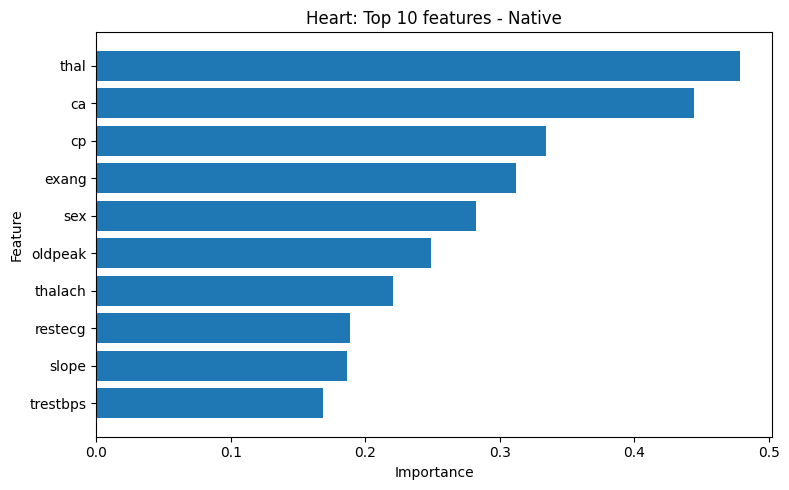

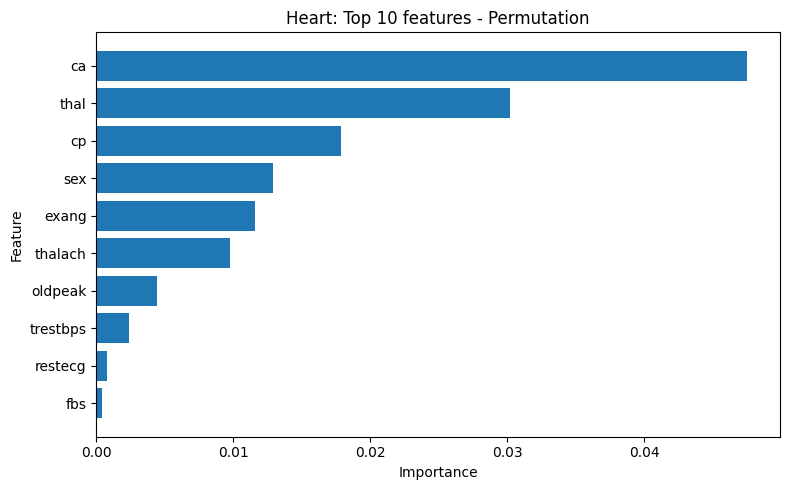

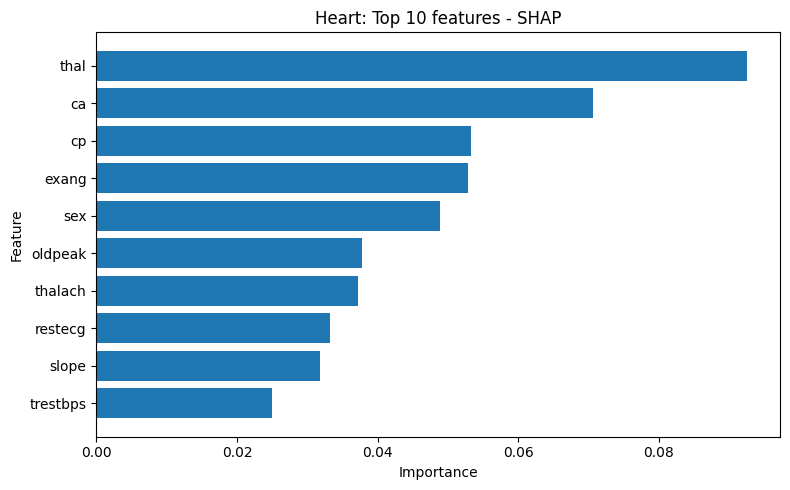

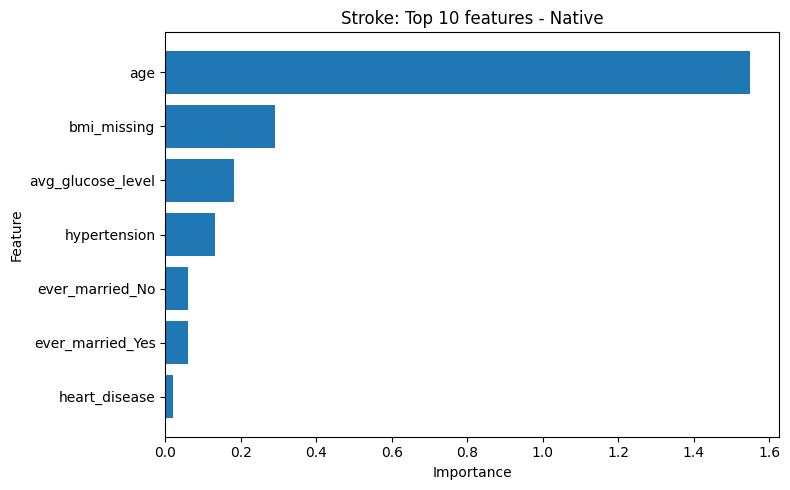

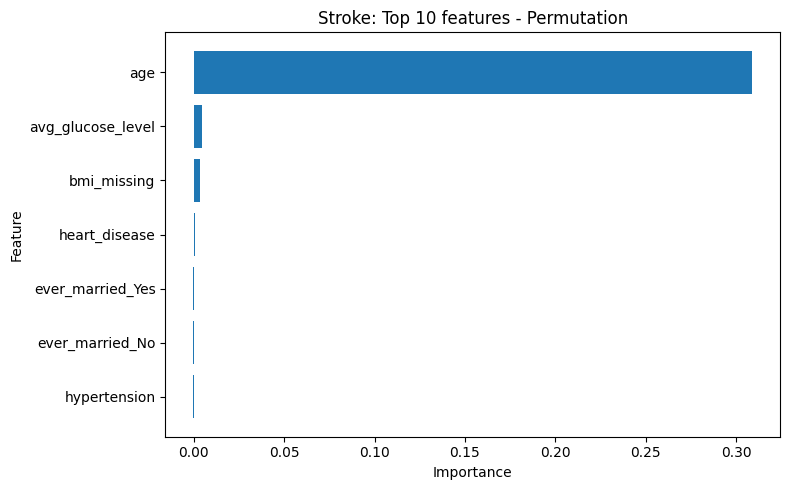

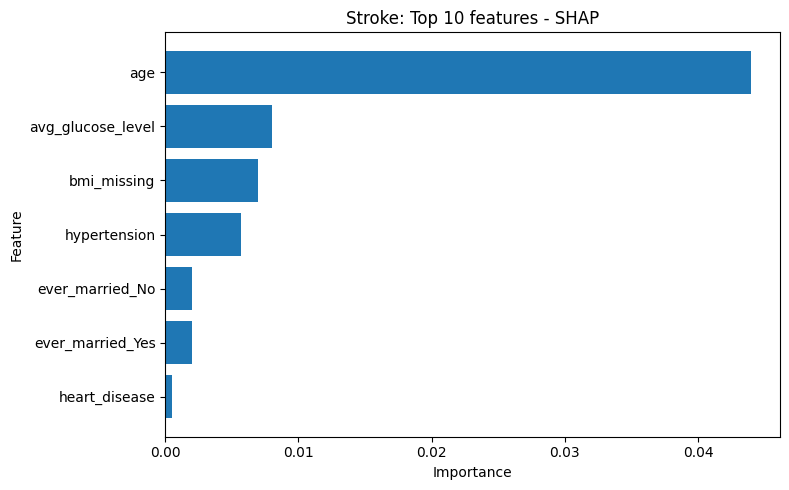

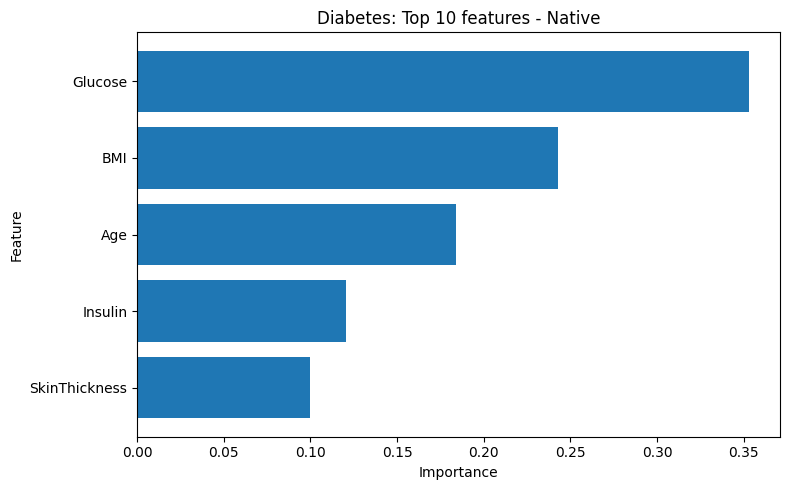

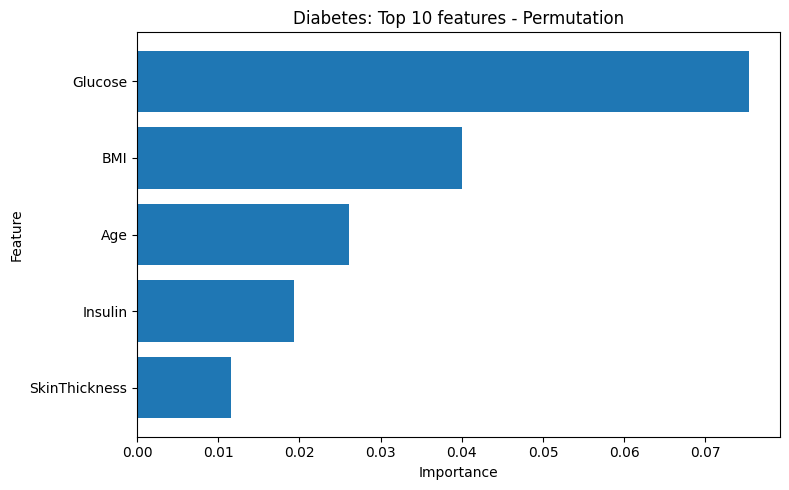

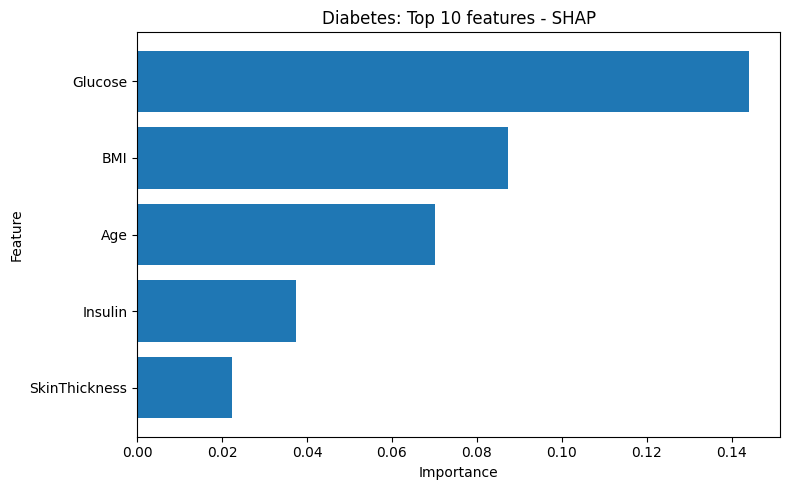

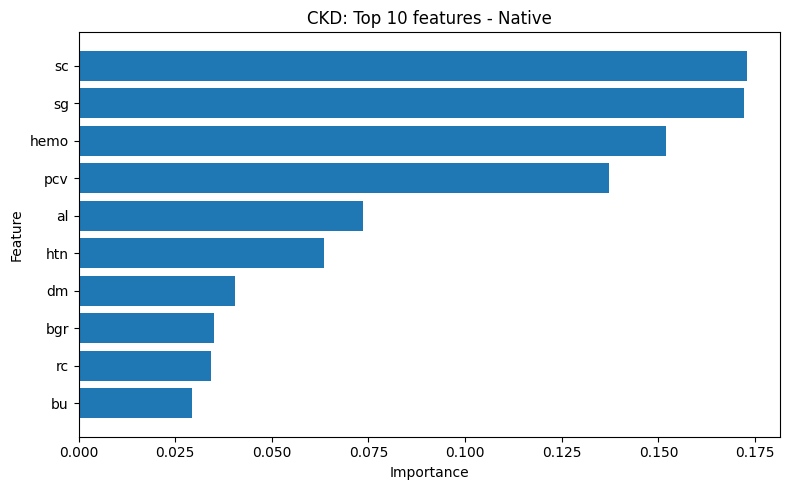

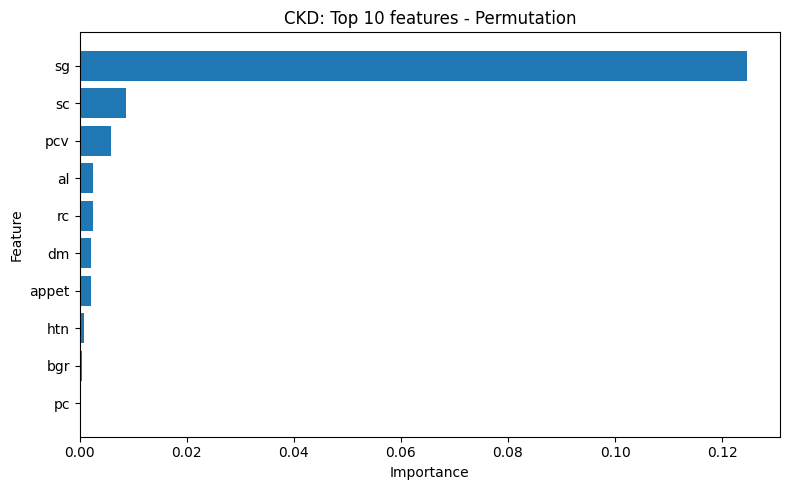

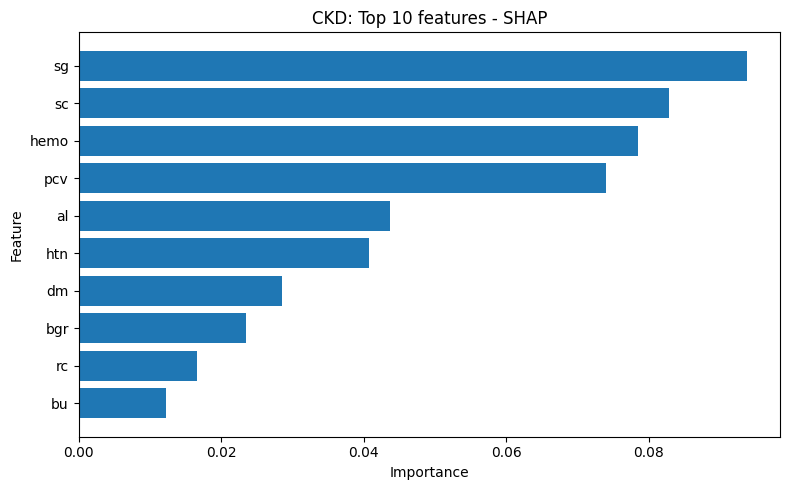

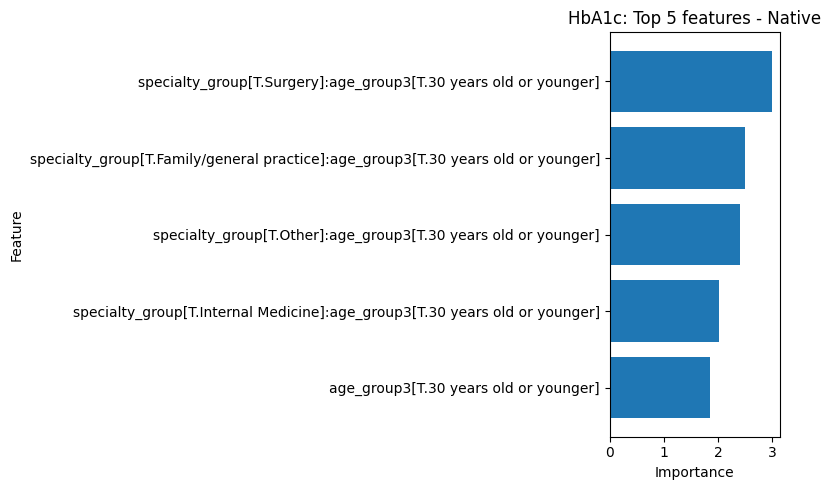

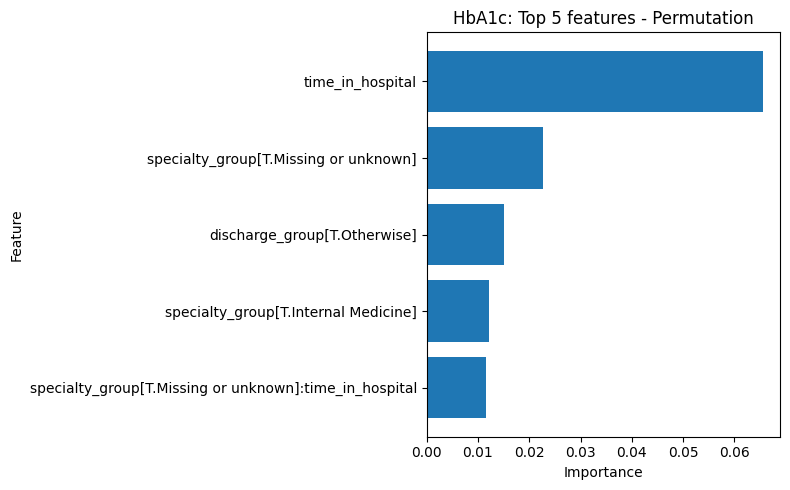

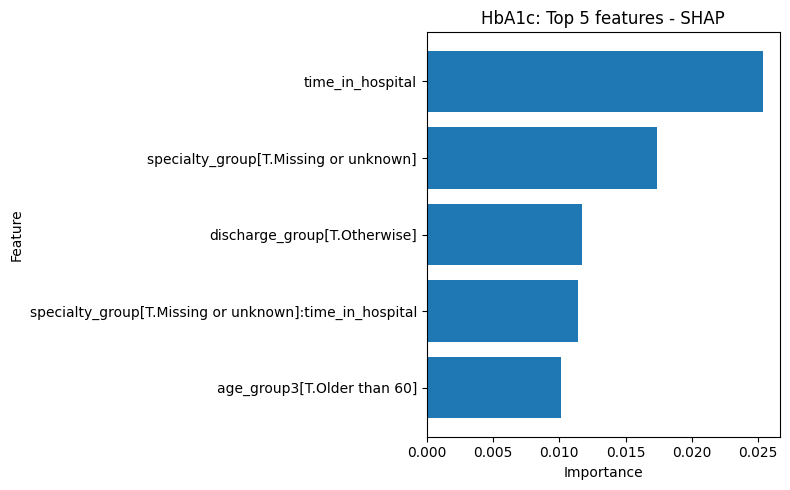

In [108]:
for dataset in DATASETS:

    if dataset == "hba1c":
        plot_global_importance(
            dataset,
            top_n=5
        )

    else:
        plot_global_importance(
            dataset,
            top_n=10
        )

In [109]:
ANALYSIS_OUT = RESULTS_DIR / "cross_dataset"

ANALYSIS_OUT.mkdir(
    parents=True,
    exist_ok=True
)

global_top5_df.to_csv(
    ANALYSIS_OUT / "global_top5_features.csv",
    index=False
)

global_overlap_df.to_csv(
    ANALYSIS_OUT / "global_top5_overlap.csv",
    index=False
)

common_global_features_df.to_csv(
    ANALYSIS_OUT / "global_common_top5_features.csv",
    index=False
)

print("4.2 Global XAI analysis exported.")

4.2 Global XAI analysis exported.


In [110]:
all_global_rank_tables = []

for dataset in DATASETS:

    df = global_rank_table(dataset).copy()

    df.insert(
        0,
        "Dataset",
        {
            "ckd": "CKD",
            "hba1c": "HbA1c"
        }.get(
            dataset,
            dataset.capitalize()
        )
    )

    all_global_rank_tables.append(df)


global_rank_all_df = pd.concat(
    all_global_rank_tables,
    ignore_index=True
)


global_rank_all_df.to_csv(
    ANALYSIS_OUT / "global_rank_comparison_all_features.csv",
    index=False
)

# D. XAI Stability Analysis

#### 1. Feature-level stability

In [111]:
def load_feature_stability(dataset):
    path = RESULTS_DIR / dataset / "stability_summary.csv"

    if not path.exists():
        return None

    return pd.read_csv(path)

In [112]:
for dataset in [
    "heart",
    "stroke",
    "diabetes",
    "ckd"
]:
    stability = load_feature_stability(dataset)

    print("\n", dataset.upper())

    display(
        stability
        .sort_values("MeanImportance", ascending=False)
        .head(10)
        .round(4)
    )


 HEART


,Feature,MeanImportance,StdImportance,MeanRank,StdRank
0,ca,0.0477,0.0031,1.0,0.0000
1,thal,0.0311,0.0053,2.0,0.0000
2,sex,0.0187,0.0012,3.4,0.5477
3,cp,0.0182,0.0028,3.6,0.5477
4,exang,0.0111,0.0028,5.4,0.5477
5,thalach,0.0104,0.0019,5.6,0.5477
6,oldpeak,0.0061,0.0017,7.0,0.0000
7,trestbps,0.0019,0.0024,9.8,2.1679
8,restecg,0.0015,0.0009,9.2,0.8367
9,slope,0.0010,0.0017,9.8,1.9235



 STROKE


,Feature,MeanImportance,StdImportance,MeanRank,StdRank
0,age,0.3035,0.0098,1.0,0.0000
1,avg_glucose_level,0.0055,0.0013,2.0,0.0000
2,bmi_missing,0.0015,0.0024,4.0,1.7321
3,heart_disease,0.0008,0.0001,3.6,0.5477
4,hypertension,-0.0006,0.0004,5.6,1.3416
5,ever_married_Yes,-0.0007,0.0005,5.9,0.5477
6,ever_married_No,-0.0007,0.0005,5.9,0.5477



 DIABETES


,Feature,MeanImportance,StdImportance,MeanRank,StdRank
0,Glucose,0.0606,0.0092,1.0,0.0000
1,BMI,0.0319,0.0072,2.0,0.0000
2,Age,0.0179,0.0092,3.2,0.4472
3,Insulin,0.0163,0.0079,3.8,0.4472
4,SkinThickness,0.0015,0.0050,5.0,0.0000



 CKD


,Feature,MeanImportance,StdImportance,MeanRank,StdRank
0,sg,0.1042,0.0295,1.0,0.0000
1,sc,0.0057,0.0034,2.5,0.7071
2,pcv,0.0020,0.0069,15.6,10.6911
3,rbc,0.0005,0.0011,10.1,3.9275
4,rc,0.0003,0.0007,10.4,3.3053
5,htn,0.0003,0.0017,11.4,9.8387
6,age,0.0000,0.0000,12.1,1.5572
7,ane,0.0000,0.0000,12.1,1.5572
8,pot,0.0000,0.0000,12.1,1.5572
9,sod,0.0000,0.0000,12.1,1.5572


#### 2. Representative-case analysis

In [113]:
def feature_stability_analysis(dataset):
    df = load_feature_stability(dataset)

    if df is None:
        return None

    df = df.copy()

    df["ImportanceCV"] = (
        df["StdImportance"]
        / df["MeanImportance"].abs().replace(0, np.nan)
    )

    return df

In [114]:
stability_feature_rows = []

for dataset in [
    "heart",
    "stroke",
    "diabetes",
    "ckd"
]:

    df = feature_stability_analysis(dataset)

    top = (
        df
        .sort_values("MeanImportance", ascending=False)
        .head(10)
    )

    top["Dataset"] = dataset.capitalize()

    stability_feature_rows.append(top)

feature_stability_df = pd.concat(
    stability_feature_rows,
    ignore_index=True
)

display(feature_stability_df.round(4))

,Feature,MeanImportance,StdImportance,MeanRank,StdRank,ImportanceCV,Dataset
0,ca,0.0477,0.0031,1.0,0.0000,0.0641,Heart
1,thal,0.0311,0.0053,2.0,0.0000,0.1713,Heart
2,sex,0.0187,0.0012,3.4,0.5477,0.0655,Heart
3,cp,0.0182,0.0028,3.6,0.5477,0.1542,Heart
4,exang,0.0111,0.0028,5.4,0.5477,0.2518,Heart
5,thalach,0.0104,0.0019,5.6,0.5477,0.1828,Heart
6,oldpeak,0.0061,0.0017,7.0,0.0000,0.2724,Heart
7,trestbps,0.0019,0.0024,9.8,2.1679,1.2804,Heart
8,restecg,0.0015,0.0009,9.2,0.8367,0.6095,Heart
9,slope,0.0010,0.0017,9.8,1.9235,1.7114,Heart


# E. Local Explanation Analysis

In [115]:
test_cases = pd.read_csv(
    RESULTS_DIR / "heart" / "representative_cases.csv"
)

print(test_cases.columns.tolist())
display(test_cases.head())

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'y_true', 'y_pred', 'y_prob', 'distance', 'CaseType', 'CaseIndex']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,y_true,y_pred,y_prob,distance,CaseType,CaseIndex
0,0.161372,-1.446980,0.873880,3.851964,0.783083,2.430427,1.010199,-0.724769,1.435916,2.529248,2.264145,1.411625,1.172577,1,1,0.961788,0.461788,TP,11
1,-0.945498,-1.446980,-1.202459,-1.505317,-0.835103,-0.411450,-1.003419,0.978071,-0.696419,-0.906712,-0.976583,-0.721976,-0.894220,0,0,0.043685,0.456315,TN,35
2,1.046868,0.691095,0.873880,-0.208291,0.301480,-0.411450,-1.003419,-1.947322,1.435916,-0.734914,0.643781,0.344824,1.172577,0,1,0.861122,0.361122,FP,82
3,1.157555,0.691095,-2.240629,0.355633,0.667499,2.430427,1.010199,1.065396,-0.696419,0.295874,0.643781,0.344824,-0.894220,1,0,0.247055,0.252945,FN,64
4,0.382746,0.691095,0.873880,-1.787279,-0.257179,-0.411450,-1.003419,0.279470,-0.696419,-0.820813,-0.976583,0.344824,1.172577,1,0,0.492082,0.007918,Borderline,9


#### 1. Local explanation analysis

In [116]:
local_case_rows = []

for dataset in DATASETS:
    path = RESULTS_DIR / dataset / "representative_cases.csv"

    if not path.exists():
        continue

    cases = pd.read_csv(path)

    if "CaseType" not in cases.columns:
        continue

    for _, row in cases.iterrows():
        local_case_rows.append({
            "Dataset": dataset.capitalize(),
            "CaseType": row.get("CaseType"),
            "True": row.get("y_true"),
            "Predicted": row.get("y_pred"),
            "Probability": row.get("y_prob")
        })

local_cases_df = pd.DataFrame(local_case_rows)

local_cases_df["Dataset"] = local_cases_df["Dataset"].replace({
    "Ckd": "CKD",
    "Hba1c": "HbA1c"
})

display(local_cases_df.round(4))

,Dataset,CaseType,True,Predicted,Probability
0,Heart,TP,1.0,1,0.9618
1,Heart,TN,0.0,0,0.0437
2,Heart,FP,0.0,1,0.8611
3,Heart,FN,1.0,0,0.2471
4,Heart,Borderline,1.0,0,0.4921
5,Stroke,TP,1.0,1,0.5492
6,Stroke,TN,0.0,0,0.0008
7,Stroke,FP,0.0,1,0.6450
8,Stroke,FN,1.0,0,0.0021
9,Stroke,Borderline,0.0,1,0.5084


In [117]:
case_availability = (
    local_cases_df
    .assign(Available=1)
    .pivot_table(
        index="Dataset",
        columns="CaseType",
        values="Available",
        aggfunc="max",
        fill_value=0
    )
    .reset_index()
)

display(case_availability)

CaseType,Dataset,Borderline,FN,FP,TN,TP
0,CKD,0,1,1,1,1
1,Diabetes,1,1,1,1,1
2,HbA1c,1,1,0,1,0
3,Heart,1,1,1,1,1
4,Stroke,1,1,1,1,1


#### 2. LIME analysis

In [122]:
case_map_rows = []

for dataset in DATASETS:

    path = (
        RESULTS_DIR
        / dataset
        / "representative_cases.csv"
    )

    if not path.exists():
        continue

    cases = pd.read_csv(path)

    if "CaseIndex" not in cases.columns:
        raise ValueError(
            f"{dataset}: representative_cases.csv "
            "does not contain CaseIndex"
        )

    display_name = {
        "ckd": "CKD",
        "hba1c": "HbA1c"
    }.get(
        dataset,
        dataset.capitalize()
    )

    for _, row in cases.iterrows():

        case_map_rows.append({
            "Dataset": display_name,
            "CaseIndex": row["CaseIndex"],
            "CaseType": row["CaseType"]
        })


case_map_df = pd.DataFrame(
    case_map_rows
)

display(case_map_df)

,Dataset,CaseIndex,CaseType
0,Heart,11,TP
1,Heart,35,TN
2,Heart,82,FP
3,Heart,64,FN
4,Heart,9,Borderline
5,Stroke,207,TP
6,Stroke,662,TN
7,Stroke,96,FP
8,Stroke,553,FN
9,Stroke,250,Borderline


In [123]:
lime_rows = []

for dataset in DATASETS:
    path = RESULTS_DIR / dataset / "lime_explanations.csv"

    if not path.exists():
        continue

    lime = pd.read_csv(path)

    if lime.empty:
        continue

    for case_idx, group in lime.groupby("CaseIndex"):

        strongest = (
            group
            .assign(AbsWeight=group["Weight"].abs())
            .sort_values("AbsWeight", ascending=False)
            .head(5)
        )

        for rank, (_, row) in enumerate(
            strongest.iterrows(),
            start=1
        ):
            lime_rows.append({
                "Dataset": dataset.capitalize(),
                "CaseIndex": case_idx,
                "Rank": rank,
                "Rule": row["Rule"],
                "Weight": row["Weight"],
                "Probability": row.get("Probability")
            })

lime_summary_df = pd.DataFrame(lime_rows)

lime_summary_df["Dataset"] = lime_summary_df["Dataset"].replace({
    "Ckd": "CKD",
    "Hba1c": "HbA1c"
})

display(lime_summary_df.head(30))

,Dataset,CaseIndex,Rank,Rule,Weight,Probability
0,Heart,9,1,-0.16 < cp <= 0.87,0.132898,0.492082
1,Heart,9,2,-0.89 < thal <= 1.17,0.094087,0.492082
2,Heart,9,3,exang <= -0.70,-0.088317,0.492082
3,Heart,9,4,fbs <= -0.41,0.063443,0.492082
4,Heart,9,5,-0.91 < oldpeak <= -0.22,-0.059946,0.492082
5,Heart,11,1,ca > 0.34,0.134002,0.961788
6,Heart,11,2,-0.16 < cp <= 0.87,0.124234,0.961788
7,Heart,11,3,-0.89 < thal <= 1.17,0.096627,0.961788
8,Heart,11,4,-0.70 < exang <= 1.44,0.088358,0.961788
9,Heart,11,5,oldpeak > 0.47,0.081193,0.961788


In [124]:
lime_with_cases_df = lime_summary_df.merge(
    case_map_df,
    on=[
        "Dataset",
        "CaseIndex"
    ],
    how="left"
)

display(lime_with_cases_df.head(30))

,Dataset,CaseIndex,Rank,Rule,Weight,Probability,CaseType
0,Heart,9,1,-0.16 < cp <= 0.87,0.132898,0.492082,Borderline
1,Heart,9,2,-0.89 < thal <= 1.17,0.094087,0.492082,Borderline
2,Heart,9,3,exang <= -0.70,-0.088317,0.492082,Borderline
3,Heart,9,4,fbs <= -0.41,0.063443,0.492082,Borderline
4,Heart,9,5,-0.91 < oldpeak <= -0.22,-0.059946,0.492082,Borderline
5,Heart,11,1,ca > 0.34,0.134002,0.961788,TP
6,Heart,11,2,-0.16 < cp <= 0.87,0.124234,0.961788,TP
7,Heart,11,3,-0.89 < thal <= 1.17,0.096627,0.961788,TP
8,Heart,11,4,-0.70 < exang <= 1.44,0.088358,0.961788,TP
9,Heart,11,5,oldpeak > 0.47,0.081193,0.961788,TP


In [125]:
lime_with_cases_df["Direction"] = np.where(
    lime_with_cases_df["Weight"] > 0,
    "Supports positive class",
    "Supports negative class"
)

display(
    lime_with_cases_df[
        [
            "Dataset",
            "CaseType",
            "CaseIndex",
            "Rank",
            "Rule",
            "Weight",
            "Direction"
        ]
    ].head(40)
)

,Dataset,CaseType,CaseIndex,Rank,Rule,Weight,Direction
0,Heart,Borderline,9,1,-0.16 < cp <= 0.87,0.132898,Supports positive class
1,Heart,Borderline,9,2,-0.89 < thal <= 1.17,0.094087,Supports positive class
2,Heart,Borderline,9,3,exang <= -0.70,-0.088317,Supports negative class
3,Heart,Borderline,9,4,fbs <= -0.41,0.063443,Supports positive class
4,Heart,Borderline,9,5,-0.91 < oldpeak <= -0.22,-0.059946,Supports negative class
5,Heart,TP,11,1,ca > 0.34,0.134002,Supports positive class
6,Heart,TP,11,2,-0.16 < cp <= 0.87,0.124234,Supports positive class
7,Heart,TP,11,3,-0.89 < thal <= 1.17,0.096627,Supports positive class
8,Heart,TP,11,4,-0.70 < exang <= 1.44,0.088358,Supports positive class
9,Heart,TP,11,5,oldpeak > 0.47,0.081193,Supports positive class


In [126]:
lime_with_cases_df["OutcomeGroup"] = (
    lime_with_cases_df["CaseType"]
    .replace({
        "TP": "Correct",
        "TN": "Correct",
        "FP": "Error",
        "FN": "Error",
        "Borderline": "Borderline"
    })
)

In [127]:
case_strength_summary = (
    lime_with_cases_df
    .assign(AbsWeight=lime_with_cases_df["Weight"].abs())
    .groupby(
        ["Dataset", "CaseType"],
        dropna=False
    )
    .agg(
        MeanAbsLIMEWeight=("AbsWeight", "mean"),
        MaxAbsLIMEWeight=("AbsWeight", "max"),
        NRules=("Rule", "count")
    )
    .reset_index()
)

display(case_strength_summary.round(4))

,Dataset,CaseType,MeanAbsLIMEWeight,MaxAbsLIMEWeight,NRules
0,CKD,FN,0.0656,0.0983,5
1,CKD,FP,0.0723,0.0879,5
2,CKD,TN,0.0883,0.0982,5
3,CKD,TP,0.0591,0.0687,5
4,Diabetes,Borderline,0.0507,0.1320,5
5,Diabetes,FN,0.0817,0.1953,5
6,Diabetes,FP,0.1277,0.3521,5
7,Diabetes,TN,0.0985,0.1972,5
8,Diabetes,TP,0.1013,0.3720,5
9,HbA1c,Borderline,0.4026,0.4821,5


#### 3. Global-vs-local consistency

In [129]:
def global_top_features(dataset, k=5):
    _, _, shap = load_global_tables(dataset)

    return shap.nlargest(
        k,
        "MeanAbsSHAP"
    )["Feature"].tolist()

In [ ]:
global_local_case_rows = []

for dataset in DATASETS:

    display_name = {
        "ckd": "CKD",
        "hba1c": "HbA1c"
    }.get(dataset, dataset.capitalize())

    global_top = global_top_features(dataset, k=5)

    lime_path = RESULTS_DIR / dataset / "lime_explanations.csv"

    if not lime_path.exists():
        continue

    lime = pd.read_csv(lime_path)

    for case_idx, group in lime.groupby("CaseIndex"):

        lime_text = " ".join(
            group["Rule"].astype(str).tolist()
        )

        matched = [
            feature
            for feature in global_top
            if feature in lime_text
        ]

        global_local_case_rows.append({
            "Dataset": display_name,
            "CaseIndex": case_idx,
            "NGlobalTop5Matched": len(matched),
            "GlobalLocalOverlap": len(matched) / 5,
            "MatchedFeatures": ", ".join(matched)
        })


global_local_case_df = pd.DataFrame(
    global_local_case_rows
)

display(global_local_case_df.round(3))

,Dataset,CaseIndex,NGlobalTop5Matched,GlobalLocalOverlap,MatchedFeatures
0,Heart,9,4,0.8,"thal, cp, exang, sex"
1,Heart,11,4,0.8,"thal, ca, cp, exang"
2,Heart,35,5,1.0,"thal, ca, cp, exang, sex"
3,Heart,64,4,0.8,"thal, cp, exang, sex"
4,Heart,82,4,0.8,"thal, cp, exang, sex"
5,Stroke,96,5,1.0,"age, avg_glucose_level, bmi_missing, hypertens..."
6,Stroke,207,5,1.0,"age, avg_glucose_level, bmi_missing, hypertens..."
7,Stroke,250,5,1.0,"age, avg_glucose_level, bmi_missing, hypertens..."
8,Stroke,553,5,1.0,"age, avg_glucose_level, bmi_missing, hypertens..."
9,Stroke,662,5,1.0,"age, avg_glucose_level, bmi_missing, hypertens..."


In [131]:
case_availability.to_csv(
    ANALYSIS_OUT / "local_case_availability.csv",
    index=False
)

lime_with_cases_df.to_csv(
    ANALYSIS_OUT / "lime_by_representative_case.csv",
    index=False
)

case_strength_summary.to_csv(
    ANALYSIS_OUT / "lime_case_strength_summary.csv",
    index=False
)

global_local_case_df.to_csv(
    ANALYSIS_OUT / "global_local_overlap_by_case.csv",
    index=False
)

print("4.5 Local explanation analysis exported.")

4.5 Local explanation analysis exported.


In [132]:
outcome_strength_summary = (
    lime_with_cases_df
    .assign(
        AbsWeight=lambda x: x["Weight"].abs()
    )
    .groupby(
        ["Dataset", "OutcomeGroup"],
        dropna=False
    )
    .agg(
        MeanAbsLIMEWeight=(
            "AbsWeight",
            "mean"
        ),
        MaxAbsLIMEWeight=(
            "AbsWeight",
            "max"
        ),
        NRules=(
            "Rule",
            "count"
        )
    )
    .reset_index()
)

display(
    outcome_strength_summary.round(4)
)

,Dataset,OutcomeGroup,MeanAbsLIMEWeight,MaxAbsLIMEWeight,NRules
0,CKD,Correct,0.0737,0.0982,10
1,CKD,Error,0.0689,0.0983,10
2,Diabetes,Borderline,0.0507,0.1320,5
3,Diabetes,Correct,0.0999,0.3720,10
4,Diabetes,Error,0.1047,0.3521,10
5,HbA1c,Borderline,0.4026,0.4821,5
6,HbA1c,Correct,0.4073,0.4643,5
7,HbA1c,Error,0.3818,0.4631,5
8,Heart,Borderline,0.0877,0.1329,5
9,Heart,Correct,0.0998,0.1340,10


# F. Framework Generalizability

#### 1. Framework capability summary

In [133]:
framework_summary = pd.DataFrame([
    {
        "Dataset": "Heart",
        "ModelFamily": "Linear classification",
        "InputRepresentation": "NumPy",
        "NativeImportance": True,
        "Permutation": True,
        "SHAP": True,
        "LIME": True,
        "Stability": True
    },
    {
        "Dataset": "Stroke",
        "ModelFamily": "Linear classification",
        "InputRepresentation": "NumPy",
        "NativeImportance": True,
        "Permutation": True,
        "SHAP": True,
        "LIME": True,
        "Stability": True
    },
    {
        "Dataset": "Diabetes",
        "ModelFamily": "Tree ensemble",
        "InputRepresentation": "DataFrame",
        "NativeImportance": True,
        "Permutation": True,
        "SHAP": True,
        "LIME": True,
        "Stability": True
    },
    {
        "Dataset": "CKD",
        "ModelFamily": "Tree ensemble",
        "InputRepresentation": "DataFrame",
        "NativeImportance": True,
        "Permutation": True,
        "SHAP": True,
        "LIME": True,
        "Stability": True
    },
    {
        "Dataset": "HbA1c",
        "ModelFamily": "Statsmodels logistic regression",
        "InputRepresentation": "Patsy design matrix",
        "NativeImportance": True,
        "Permutation": True,
        "SHAP": True,
        "LIME": True,
        "Stability": False
    }
])

display(framework_summary)

,Dataset,ModelFamily,InputRepresentation,NativeImportance,Permutation,SHAP,LIME,Stability
0,Heart,Linear classification,NumPy,True,True,True,True,True
1,Stroke,Linear classification,NumPy,True,True,True,True,True
2,Diabetes,Tree ensemble,DataFrame,True,True,True,True,True
3,CKD,Tree ensemble,DataFrame,True,True,True,True,True
4,HbA1c,Statsmodels logistic regression,Patsy design matrix,True,True,True,True,False


# G. Export Consolidated Results

#### 1. Export additional analysis tables

In [135]:
ANALYSIS_OUT = RESULTS_DIR / "cross_dataset"

ANALYSIS_OUT.mkdir(
    parents=True,
    exist_ok=True
)

# 4.2 Global XAI
global_overlap_df.to_csv(
    ANALYSIS_OUT / "global_top5_overlap.csv",
    index=False
)

common_global_features_df.to_csv(
    ANALYSIS_OUT / "global_common_top5_features.csv",
    index=False
)

# 4.5 Local XAI
local_cases_df.to_csv(
    ANALYSIS_OUT / "representative_cases_all_datasets.csv",
    index=False
)

lime_summary_df.to_csv(
    ANALYSIS_OUT / "lime_summary_all_datasets.csv",
    index=False
)

case_availability.to_csv(
    ANALYSIS_OUT / "local_case_availability.csv",
    index=False
)

lime_with_cases_df.to_csv(
    ANALYSIS_OUT / "lime_by_representative_case.csv",
    index=False
)

case_strength_summary.to_csv(
    ANALYSIS_OUT / "lime_case_strength_summary.csv",
    index=False
)

global_local_case_df.to_csv(
    ANALYSIS_OUT / "global_local_overlap_by_case.csv",
    index=False
)

outcome_strength_summary.to_csv(
    ANALYSIS_OUT / "lime_correct_vs_error_summary.csv",
    index=False
)

# 4.4 Stability
feature_stability_df.to_csv(
    ANALYSIS_OUT / "feature_level_stability.csv",
    index=False
)

# 4.7 Framework summary
framework_summary.to_csv(
    ANALYSIS_OUT / "framework_capability_summary.csv",
    index=False
)

print("Additional analysis exported.")

Additional analysis exported.
